In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

thermo_data = {
    "Species": ["CO2", "H2", "CH3OH", "H2O", "CO"],
    "Phase": ["Gas"] * 5,
    "Hf_kJ_mol": [-393.51, 0.00, None, -241.83, -110.53],
    "S_J_mol_K": [213.79, 130.68, None, 188.84, 197.66]
}

thermo_df = pd.DataFrame(thermo_data)

display(thermo_df)

,Species,Phase,Hf_kJ_mol,S_J_mol_K
0,CO2,Gas,-393.51,213.79
1,H2,Gas,0.00,130.68
2,CH3OH,Gas,NaN,NaN
3,H2O,Gas,-241.83,188.84
4,CO,Gas,-110.53,197.66


In [3]:
thermo_df.loc[thermo_df["Species"] == "CH3OH", "Hf_kJ_mol"] = -201.00
thermo_df.loc[thermo_df["Species"] == "CH3OH", "S_J_mol_K"] = 239.87

display(thermo_df)

,Species,Phase,Hf_kJ_mol,S_J_mol_K
0,CO2,Gas,-393.51,213.79
1,H2,Gas,0.00,130.68
2,CH3OH,Gas,-201.00,239.87
3,H2O,Gas,-241.83,188.84
4,CO,Gas,-110.53,197.66


In [4]:
# Methanol synthesis:
# CO2 + 3H2 -> CH3OH + H2O

# Reverse water-gas shift:
# CO2 + H2 -> CO + H2O

data = thermo_df.set_index("Species")

# Reaction 1: Methanol synthesis
dH1 = (
    data.loc["CH3OH", "Hf_kJ_mol"]
    + data.loc["H2O", "Hf_kJ_mol"]
    - data.loc["CO2", "Hf_kJ_mol"]
    - 3 * data.loc["H2", "Hf_kJ_mol"]
)

dS1 = (
    data.loc["CH3OH", "S_J_mol_K"]
    + data.loc["H2O", "S_J_mol_K"]
    - data.loc["CO2", "S_J_mol_K"]
    - 3 * data.loc["H2", "S_J_mol_K"]
)

# Reaction 2: Reverse water-gas shift
dH2 = (
    data.loc["CO", "Hf_kJ_mol"]
    + data.loc["H2O", "Hf_kJ_mol"]
    - data.loc["CO2", "Hf_kJ_mol"]
    - data.loc["H2", "Hf_kJ_mol"]
)

dS2 = (
    data.loc["CO", "S_J_mol_K"]
    + data.loc["H2O", "S_J_mol_K"]
    - data.loc["CO2", "S_J_mol_K"]
    - data.loc["H2", "S_J_mol_K"]
)

results = pd.DataFrame({
    "Reaction": ["Methanol synthesis", "Reverse water-gas shift"],
    "Delta_H_kJ_mol": [dH1, dH2],
    "Delta_S_J_mol_K": [dS1, dS2]
})

display(results.round(3))

,Reaction,Delta_H_kJ_mol,Delta_S_J_mol_K
0,Methanol synthesis,-49.32,-177.12
1,Reverse water-gas shift,41.15,42.03


In [5]:
T_ref = 298.15  # K

results["Delta_G_kJ_mol"] = (
    results["Delta_H_kJ_mol"]
    - T_ref * results["Delta_S_J_mol_K"] / 1000
)

display(results.round(3))

,Reaction,Delta_H_kJ_mol,Delta_S_J_mol_K,Delta_G_kJ_mol
0,Methanol synthesis,-49.32,-177.12,3.488
1,Reverse water-gas shift,41.15,42.03,28.619


In [6]:
R = 0.008314  # kJ/(mol K)

results["Kp_298"] = np.exp(
    -results["Delta_G_kJ_mol"] / (R * T_ref)
)

display(results.round(6))

,Reaction,Delta_H_kJ_mol,Delta_S_J_mol_K,Delta_G_kJ_mol,Kp_298
0,Methanol synthesis,-49.32,-177.12,3.488328,0.244815
1,Reverse water-gas shift,41.15,42.03,28.618755,0.000010


In [7]:
sources = {
    "CO2": "NIST Chemistry WebBook - CODATA/Chase",
    "H2": "NIST Chemistry WebBook - CODATA/Chase",
    "CH3OH": "NIST CCCBDB - Gurvich",
    "H2O": "NIST Chemistry WebBook - CODATA/Chase",
    "CO": "NIST Chemistry WebBook - CODATA/Chase"
}

thermo_df["Source"] = thermo_df["Species"].map(sources)

display(thermo_df)

,Species,Phase,Hf_kJ_mol,S_J_mol_K,Source
0,CO2,Gas,-393.51,213.79,NIST Chemistry WebBook - CODATA/Chase
1,H2,Gas,0.00,130.68,NIST Chemistry WebBook - CODATA/Chase
2,CH3OH,Gas,-201.00,239.87,NIST CCCBDB - Gurvich
3,H2O,Gas,-241.83,188.84,NIST Chemistry WebBook - CODATA/Chase
4,CO,Gas,-110.53,197.66,NIST Chemistry WebBook - CODATA/Chase


In [8]:
# NIST Shomate coefficients for CO2(g), 298–1200 K
A = 24.99735
B = 55.18696
C = -33.69137
D = 7.948387
E = -0.136638

def cp_CO2(T):
    t = T / 1000
    return A + B*t + C*t**2 + D*t**3 + E/t**2

temperatures = [298.15, 400, 500, 600, 700]

cp_values = pd.DataFrame({
    "Temperature_K": temperatures,
    "CO2_Cp_J_mol_K": [cp_CO2(T) for T in temperatures]
})

display(cp_values.round(3))

,Temperature_K,CO2_Cp_J_mol_K
0,298.15,37.130
1,400.00,41.336
2,500.00,44.615
3,600.00,47.318
4,700.00,49.567


In [9]:
# NIST Shomate coefficients
# Cp = A + B*t + C*t^2 + D*t^3 + E/t^2
# t = T/1000

shomate = {
    "CO2": (24.99735, 55.18696, -33.69137, 7.948387, -0.136638),
    "H2": (33.066178, -11.363417, 11.432816, -2.772874, -0.158558),
    "H2O": (30.09200, 6.832514, 6.793435, -2.534480, 0.082139),
    "CO": (25.56759, 6.096130, 4.054656, -2.671301, 0.131021)
}

def cp_shomate(T, coeff):
    A, B, C, D, E = coeff
    t = T / 1000
    return A + B*t + C*t**2 + D*t**3 + E/t**2

temperatures = [500, 600, 700, 800, 900, 1000]

cp_table = pd.DataFrame({
    "Temperature_K": temperatures
})

for species, coeff in shomate.items():
    cp_table[f"{species}_Cp_J_mol_K"] = [
        cp_shomate(T, coeff) for T in temperatures
    ]

display(cp_table.round(3))

,Temperature_K,CO2_Cp_J_mol_K,H2_Cp_J_mol_K,H2O_Cp_J_mol_K,CO_Cp_J_mol_K
0,500,44.615,29.262,35.218,29.819
1,600,47.318,29.325,36.318,30.472
2,700,49.567,29.439,37.502,31.173
3,800,51.441,29.625,38.736,31.876
4,900,53.001,29.883,39.998,32.553
5,1000,54.305,30.204,41.266,33.178


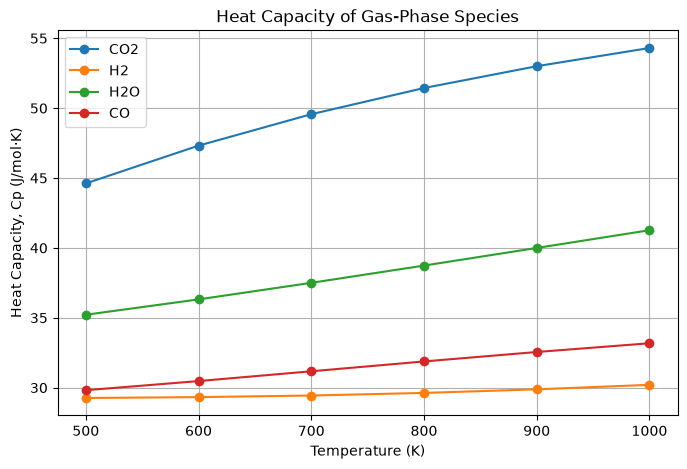

In [10]:
plt.figure(figsize=(8, 5))

for species in shomate:
    plt.plot(
        cp_table["Temperature_K"],
        cp_table[f"{species}_Cp_J_mol_K"],
        marker="o",
        label=species
    )

plt.xlabel("Temperature (K)")
plt.ylabel("Heat Capacity, Cp (J/mol·K)")
plt.title("Heat Capacity of Gas-Phase Species")
plt.legend()
plt.grid(True)
plt.show()

   ---------------------------------------- 0.0/5.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/5.3 MB ? eta -:--:--
   ------------------- -------------------- 2.6/5.3 MB 10.8 MB/s eta 0:00:01
   ---------------------------------------- 5.3/5.3 MB 12.6 MB/s  0:00:00

   ---------------------------------------- 0/2 [ruamel.yaml]
   ---------------------------------------- 0/2 [ruamel.yaml]
   ---------------------------------------- 0/2 [ruamel.yaml]
   ---------------------------------------- 0/2 [ruamel.yaml]
   ---------------------------------------- 0/2 [ruamel.yaml]
   -------------------- ------------------- 1/2 [cantera]
   -------------------- ------------------- 1/2 [cantera]
   -------------------- ------------------- 1/2 [cantera]
   -------------------- ------------------- 1/2 [cantera]
   -------------------- ------------------- 1/2 [cantera]
   -------------------- ------------------- 1/2 [cantera]
   -------------------- ------------------- 1/2 [can


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
%pip install cantera 

In [12]:
import cantera as ct

print("Cantera version:", ct.__version__)

Cantera version: 3.2.0


In [13]:
import cantera as ct

gas = ct.Solution("gri30.yaml")

required_species = ["CO2", "H2", "CH3OH", "H2O", "CO"]

available_species = set(gas.species_names)

for species in required_species:
    print(f"{species}: {'Available' if species in available_species else 'Not available'}")

CO2: Available
H2: Available
CH3OH: Available
H2O: Available
CO: Available


In [14]:
import cantera as ct
import pandas as pd

gas = ct.Solution("gri30.yaml")

species_list = ["CO2", "H2", "CH3OH", "H2O", "CO"]
T_ref = 298.15

thermo_rows = []

for species in species_list:
    k = gas.species_index(species)
    sp = gas.species(k)

    gas.TPX = T_ref, ct.one_atm, {species: 1.0}

    thermo_rows.append({
        "Species": species,
        "H_kJ_mol": gas.enthalpy_mole / 1000,
        "S_J_mol_K": gas.entropy_mole,
        "Cp_J_mol_K": gas.cp_mole
    })

cantera_df = pd.DataFrame(thermo_rows)
display(cantera_df.round(3))

,Species,H_kJ_mol,S_J_mol_K,Cp_J_mol_K
0,CO2,-393507.758,213786.267,37135.175
1,H2,0.000,130680.270,28836.183
2,CH3OH,-200938.855,239808.876,44039.227
3,H2O,-241824.622,188828.039,33587.519
4,CO,-110529.370,197656.317,29140.834


In [15]:
# Standard-state thermodynamic properties at 298.15 K
T_ref = 298.15
P_ref = ct.one_atm

gas.TP = T_ref, P_ref

def reaction_properties(stoich):
    # stoich: products positive, reactants negative
    delta_h = 0.0
    delta_s = 0.0

    for species, nu in stoich.items():
        gas.TPX = T_ref, P_ref, {species: 1.0}
        delta_h += nu * gas.enthalpy_mole
        delta_s += nu * gas.entropy_mole

    delta_h_kJ = delta_h / 1e6
    delta_s_J = delta_s

    delta_g_kJ = delta_h_kJ - T_ref * delta_s_J / 1000

    return delta_h_kJ, delta_s_J, delta_g_kJ

reactions = {
    "Methanol synthesis": {
        "CH3OH": 1, "H2O": 1, "CO2": -1, "H2": -3
    },
    "Reverse water-gas shift": {
        "CO": 1, "H2O": 1, "CO2": -1, "H2": -1
    }
}

rows = []

for name, stoich in reactions.items():
    dH, dS, dG = reaction_properties(stoich)
    rows.append({
        "Reaction": name,
        "Delta_H_kJ_mol": dH,
        "Delta_S_J_mol_K": dS,
        "Delta_G_kJ_mol": dG
    })

cantera_results = pd.DataFrame(rows)
display(cantera_results.round(4))

,Reaction,Delta_H_kJ_mol,Delta_S_J_mol_K,Delta_G_kJ_mol
0,Methanol synthesis,-49.2557,-177190.1604,52779.9906
1,Reverse water-gas shift,41.1538,42017.8205,-12486.4594


In [16]:
def reaction_properties(stoich):
    delta_h = 0.0
    delta_s = 0.0

    for species, nu in stoich.items():
        gas.TPX = T_ref, P_ref, {species: 1.0}

        # Cantera: J/kmol and J/kmol/K
        delta_h += nu * gas.enthalpy_mole
        delta_s += nu * gas.entropy_mole

    # Convert to kJ/mol and J/mol/K
    delta_h_kJ = delta_h / 1e6
    delta_s_J = delta_s / 1000

    delta_g_kJ = delta_h_kJ - T_ref * delta_s_J / 1000

    return delta_h_kJ, delta_s_J, delta_g_kJ

rows = []

for name, stoich in reactions.items():
    dH, dS, dG = reaction_properties(stoich)
    rows.append({
        "Reaction": name,
        "Delta_H_kJ_mol": dH,
        "Delta_S_J_mol_K": dS,
        "Delta_G_kJ_mol": dG
    })

cantera_results = pd.DataFrame(rows)
display(cantera_results.round(4))

,Reaction,Delta_H_kJ_mol,Delta_S_J_mol_K,Delta_G_kJ_mol
0,Methanol synthesis,-49.2557,-177.1902,3.5735
1,Reverse water-gas shift,41.1538,42.0178,28.6262


In [17]:
R = 8.314462618  # J/(mol K)
T_ref = 298.15   # K

cantera_results["Kp_298"] = np.exp(
    -(cantera_results["Delta_G_kJ_mol"] * 1000)
    / (R * T_ref)
)

display(cantera_results.round(6))

,Reaction,Delta_H_kJ_mol,Delta_S_J_mol_K,Delta_G_kJ_mol,Kp_298
0,Methanol synthesis,-49.255719,-177.19016,3.573527,0.236562
1,Reverse water-gas shift,41.153766,42.01782,28.626153,0.000010


In [18]:
temperatures = [300, 350, 400, 450, 500, 550, 600]
R = 8.314462618  # J/(mol K)

temperature_results = []

for T in temperatures:
    gas.TP = T, P_ref

    for name, stoich in reactions.items():
        dH = 0.0
        dS = 0.0

        for species, nu in stoich.items():
            gas.TPX = T, P_ref, {species: 1.0}
            dH += nu * gas.enthalpy_mole
            dS += nu * gas.entropy_mole

        dH_kJ = dH / 1e6
        dS_J = dS / 1000
        dG_kJ = dH_kJ - T * dS_J / 1000
        Kp = np.exp(-dG_kJ * 1000 / (R * T))

        temperature_results.append({
            "Temperature_K": T,
            "Reaction": name,
            "Delta_H_kJ_mol": dH_kJ,
            "Delta_S_J_mol_K": dS_J,
            "Delta_G_kJ_mol": dG_kJ,
            "Kp": Kp
        })

temperature_df = pd.DataFrame(temperature_results)
display(temperature_df.round(6))

,Temperature_K,Reaction,Delta_H_kJ_mol,Delta_S_J_mol_K,Delta_G_kJ_mol,Kp
0,300,Methanol synthesis,-49.340852,-177.474817,3.901593,0.209260
1,300,Reverse water-gas shift,41.147687,41.997494,28.548439,0.000011
2,350,Methanol synthesis,-51.629802,-184.533086,12.956778,0.011650
3,350,Reverse water-gas shift,40.928086,41.324493,26.464513,0.000112
4,400,Methanol synthesis,-53.852540,-190.471969,22.336248,0.001211
5,400,Reverse water-gas shift,40.619300,40.502140,24.418444,0.000648
6,450,Methanol synthesis,-55.961439,-195.442858,31.987847,0.000194
7,450,Reverse water-gas shift,40.243468,39.618135,22.415307,0.002501
8,500,Methanol synthesis,-57.927336,-199.588234,41.866781,0.000042
9,500,Reverse water-gas shift,39.818430,38.723260,20.456800,0.007293


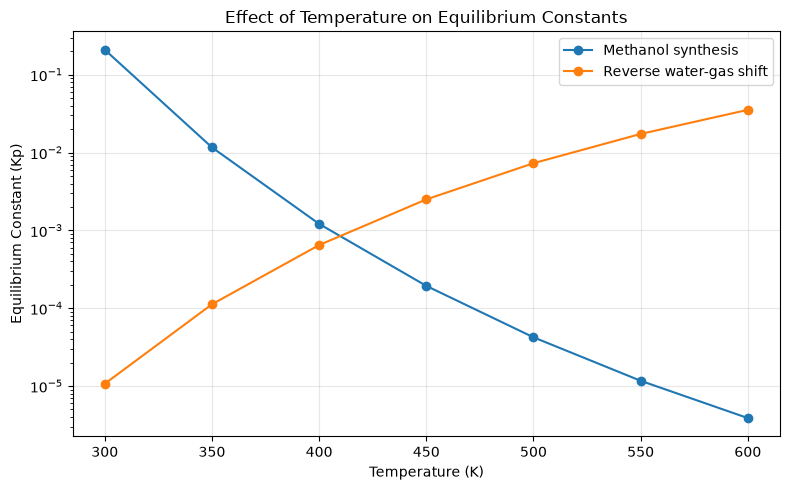

In [19]:
plt.figure(figsize=(8, 5))

for reaction in temperature_df["Reaction"].unique():
    data = temperature_df[temperature_df["Reaction"] == reaction]
    plt.plot(
        data["Temperature_K"],
        data["Kp"],
        marker="o",
        label=reaction
    )

plt.yscale("log")
plt.xlabel("Temperature (K)")
plt.ylabel("Equilibrium Constant (Kp)")
plt.title("Effect of Temperature on Equilibrium Constants")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
from scipy.optimize import minimize

T = 500                 # Temperature (K)
P_bar = 50              # Total pressure (bar)
P0_bar = 1.01325         # Standard pressure (bar), consistent with Cantera's 1 atm reference

n0 = {
    "CO2": 1.0,
    "H2": 3.0,
    "CH3OH": 0.0,
    "H2O": 0.0,
    "CO": 0.0
}

print("Temperature:", T, "K")
print("Total pressure:", P_bar, "bar")
print("Initial feed:", n0)

Temperature: 500 K
Total pressure: 50 bar
Initial feed: {'CO2': 1.0, 'H2': 3.0, 'CH3OH': 0.0, 'H2O': 0.0, 'CO': 0.0}


In [21]:
T = 500
R = 8.314462618

K_values = {}

for name, stoich in reactions.items():
    dG = 0.0

    for species, nu in stoich.items():
        gas.TPX = T, P_ref, {species: 1.0}
        h = gas.enthalpy_mole / 1e6
        s = gas.entropy_mole / 1000
        dG += nu * (h - T * s / 1000)

    K_values[name] = np.exp(-dG * 1000 / (R * T))

print("Equilibrium constants at", T, "K:")
for name, K in K_values.items():
    print(f"{name}: Kp = {K:.6g}")

Equilibrium constants at 500 K:
Methanol synthesis: Kp = 4.22954e-05
Reverse water-gas shift: Kp = 0.00729348


In [22]:
from scipy.optimize import minimize
import numpy as np

species = ["CO2", "H2", "CH3OH", "H2O", "CO"]

def calculate_moles(xi):
    xi1, xi2 = xi

    return np.array([
        1.0 - xi1 - xi2,       # CO2
        3.0 - 3.0*xi1 - xi2,   # H2
        xi1,                    # CH3OH
        xi1 + xi2,              # H2O
        xi2                     # CO
    ])

def equilibrium_objective(xi):
    n = calculate_moles(xi)

    if np.any(n <= 0):
        return 1e10

    y = n / n.sum()
    p = y * P_bar / P0_bar

    Q1 = (p[2] * p[3]) / (p[0] * p[1]**3)
    Q2 = (p[4] * p[3]) / (p[0] * p[1])

    return (
        np.log(Q1 / K_values["Methanol synthesis"])**2
        + np.log(Q2 / K_values["Reverse water-gas shift"])**2
    )

constraints = [
    {"type": "ineq", "fun": lambda xi: 1 - xi[0] - xi[1]},
    {"type": "ineq", "fun": lambda xi: 3 - 3*xi[0] - xi[1]}
]

result = minimize(
    equilibrium_objective,
    x0=[0.01, 0.05],
    method="SLSQP",
    bounds=[(0, 1), (0, 1)],
    constraints=constraints,
    options={"maxiter": 2000, "ftol": 1e-12}
)

print("Solver success:", result.success)
print("Reaction extents:", result.x)
print("Objective value:", result.fun)

Solver success: True
Reaction extents: [0.23912289 0.04182794]
Objective value: 7.522054003806366e-14


In [23]:
equilibrium_moles = calculate_moles(result.x)

equilibrium_df = pd.DataFrame({
    "Species": species,
    "Initial_moles": [n0[s] for s in species],
    "Equilibrium_moles": equilibrium_moles,
    "Mole_fraction": equilibrium_moles / equilibrium_moles.sum()
})

display(equilibrium_df.round(5))

,Species,Initial_moles,Equilibrium_moles,Mole_fraction
0,CO2,1.0,0.71905,0.20417
1,H2,3.0,2.24080,0.63627
2,CH3OH,0.0,0.23912,0.06790
3,H2O,0.0,0.28095,0.07978
4,CO,0.0,0.04183,0.01188


In [24]:
n_eq = dict(zip(species, equilibrium_moles))

co2_conversion = (
    (n0["CO2"] - n_eq["CO2"]) / n0["CO2"]
) * 100

methanol_yield = (
    n_eq["CH3OH"] / n0["CO2"]
) * 100

print(f"CO2 Conversion: {co2_conversion:.2f}%")
print(f"Methanol Yield: {methanol_yield:.2f}%")
print(f"Equilibrium Methanol: {n_eq['CH3OH']:.5f} mol")

CO2 Conversion: 28.10%
Methanol Yield: 23.91%
Equilibrium Methanol: 0.23912 mol


In [25]:
temperatures = [400, 450, 500, 550, 600]
pressures_bar = [10, 30, 50, 70]

conditions = pd.DataFrame(
    [(T, P) for T in temperatures for P in pressures_bar],
    columns=["Temperature_K", "Pressure_bar"]
)

display(conditions)

,Temperature_K,Pressure_bar
0,400,10
1,400,30
2,400,50
3,400,70
4,450,10
5,450,30
6,450,50
7,450,70
8,500,10
9,500,30


In [26]:
from scipy.optimize import minimize
import numpy as np

simulation_results = []

for T in temperatures:
    K_T = {}

    # Calculate equilibrium constants at this temperature
    for name, stoich in reactions.items():
        dG = 0.0

        for sp, nu in stoich.items():
            gas.TPX = T, P_ref, {sp: 1.0}
            h = gas.enthalpy_mole / 1e6
            s = gas.entropy_mole / 1000
            dG += nu * (h - T * s / 1000)

        K_T[name] = np.exp(-dG * 1000 / (R * T))

    for P_bar in pressures_bar:

        def objective(xi):
            n = calculate_moles(xi)

            if np.any(n <= 0):
                return 1e10

            y = n / n.sum()
            p = y * P_bar / P0_bar

            Q1 = (p[2] * p[3]) / (p[0] * p[1]**3)
            Q2 = (p[4] * p[3]) / (p[0] * p[1])

            return (
                np.log(Q1 / K_T["Methanol synthesis"])**2
                + np.log(Q2 / K_T["Reverse water-gas shift"])**2
            )

        result_TP = minimize(
            objective,
            x0=[0.01, 0.05],
            method="SLSQP",
            bounds=[(0, 1), (0, 1)],
            constraints=[
                {"type": "ineq", "fun": lambda x: 1 - x[0] - x[1]},
                {"type": "ineq", "fun": lambda x: 3 - 3*x[0] - x[1]}
            ],
            options={"maxiter": 2000, "ftol": 1e-12}
        )

        if not result_TP.success:
            print(f"Solver warning: T={T} K, P={P_bar} bar")

        n_eq = calculate_moles(result_TP.x)

        simulation_results.append({
            "Temperature_K": T,
            "Pressure_bar": P_bar,
            "CO2_Conversion_pct": (1 - n_eq[0]) * 100,
            "Methanol_Yield_pct": n_eq[2] * 100,
            "Methanol_mol": n_eq[2],
            "CO_mol": n_eq[4],
            "Solver_success": result_TP.success
        })

results_df = pd.DataFrame(simulation_results)
display(results_df.round(4))

,Temperature_K,Pressure_bar,CO2_Conversion_pct,Methanol_Yield_pct,Methanol_mol,CO_mol,Solver_success
0,400,10,27.4752,27.1020,0.2710,0.0037,True
1,400,30,47.8997,47.7894,0.4779,0.0011,True
2,400,50,57.2389,57.1768,0.5718,0.0006,True
3,400,70,62.8715,62.8289,0.6283,0.0004,True
4,450,10,15.8508,12.4072,0.1241,0.0344,True
5,450,30,31.0259,29.8623,0.2986,0.0116,True
6,450,50,40.3616,39.6954,0.3970,0.0067,True
7,450,70,46.7311,46.2728,0.4627,0.0046,True
8,500,10,14.8942,3.2863,0.0329,0.1161,True
9,500,30,21.6125,15.0443,0.1504,0.0657,True


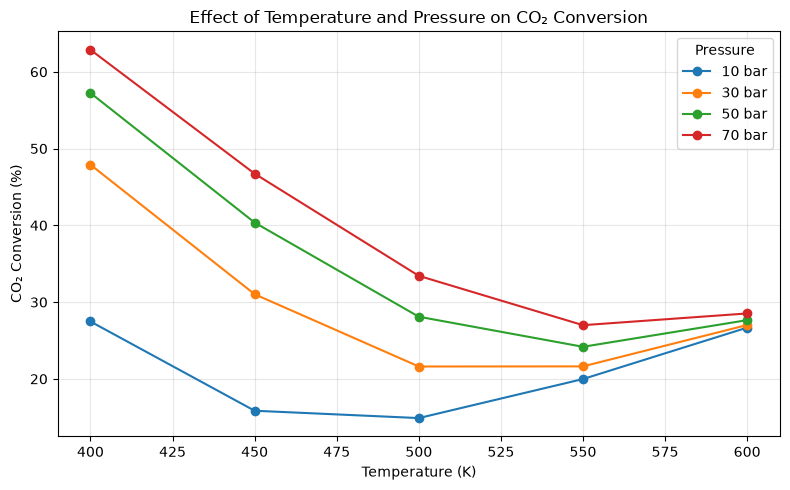

In [27]:
plt.figure(figsize=(8, 5))

for P in pressures_bar:
    data = results_df[results_df["Pressure_bar"] == P]
    plt.plot(
        data["Temperature_K"],
        data["CO2_Conversion_pct"],
        marker="o",
        label=f"{P} bar"
    )

plt.xlabel("Temperature (K)")
plt.ylabel("CO₂ Conversion (%)")
plt.title("Effect of Temperature and Pressure on CO₂ Conversion")
plt.legend(title="Pressure")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

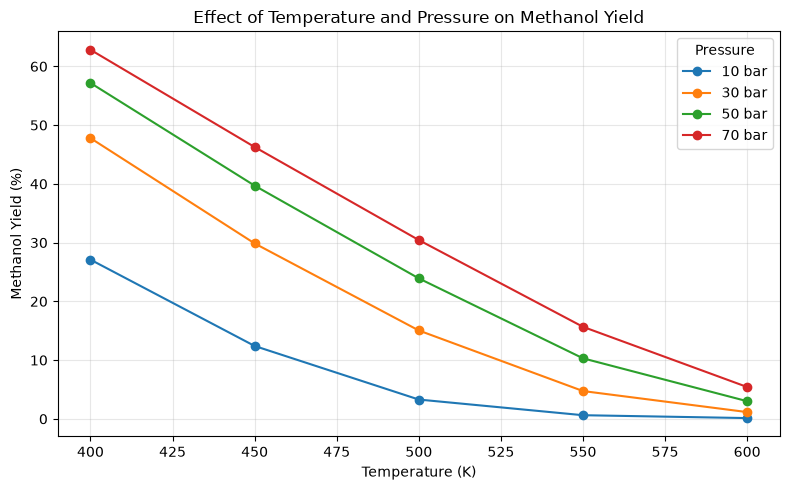

In [28]:
plt.figure(figsize=(8, 5))

for P in pressures_bar:
    data = results_df[results_df["Pressure_bar"] == P]
    plt.plot(
        data["Temperature_K"],
        data["Methanol_Yield_pct"],
        marker="o",
        label=f"{P} bar"
    )

plt.xlabel("Temperature (K)")
plt.ylabel("Methanol Yield (%)")
plt.title("Effect of Temperature and Pressure on Methanol Yield")
plt.legend(title="Pressure")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
best_condition = results_df.loc[
    results_df["Methanol_Yield_pct"].idxmax()
]

print("Best tested condition for methanol yield:")
display(best_condition.to_frame(name="Value").round(4))

Best tested condition for methanol yield:


,Value
Temperature_K,400
Pressure_bar,70
CO2_Conversion_pct,62.871529
Methanol_Yield_pct,62.828896
Methanol_mol,0.628289
CO_mol,0.000426
Solver_success,True


In [30]:
print("Total simulation cases:", len(results_df))
print("Successful cases:", results_df["Solver_success"].sum())
print("Failed cases:", (~results_df["Solver_success"]).sum())

print("\nMissing values:")
print(results_df.isnull().sum())

print("\nConversion and yield ranges:")
display(
    results_df[
        ["CO2_Conversion_pct", "Methanol_Yield_pct"]
    ].agg(["min", "max"]).round(3)
)

Total simulation cases: 20
Successful cases: 20
Failed cases: 0

Missing values:
Temperature_K         0
Pressure_bar          0
CO2_Conversion_pct    0
Methanol_Yield_pct    0
Methanol_mol          0
CO_mol                0
Solver_success        0
dtype: int64

Conversion and yield ranges:


,CO2_Conversion_pct,Methanol_Yield_pct
min,14.894,0.132
max,62.872,62.829


In [31]:
results_df.to_csv("methanol_equilibrium_results.csv", index=False)

print("Dataset exported successfully!")
print("File: methanol_equilibrium_results.csv")
print("Rows:", len(results_df))
print("Columns:", len(results_df.columns))

Dataset exported successfully!
File: methanol_equilibrium_results.csv
Rows: 20
Columns: 7


In [32]:
import os

print("Current folder:", os.getcwd())
print("CSV exists:", os.path.exists("methanol_equilibrium_results.csv"))

display(results_df.head(10))

Current folder: c:\Users\VANISREE\AppData\Local\Programs\Microsoft VS Code
CSV exists: True


,Temperature_K,Pressure_bar,CO2_Conversion_pct,Methanol_Yield_pct,Methanol_mol,CO_mol,Solver_success
0,400,10,27.475199,27.101966,0.271020,0.003732,True
1,400,30,47.899683,47.789422,0.477894,0.001103,True
2,400,50,57.238920,57.176792,0.571768,0.000621,True
3,400,70,62.871529,62.828896,0.628289,0.000426,True
4,450,10,15.850807,12.407238,0.124072,0.034436,True
5,450,30,31.025864,29.862338,0.298623,0.011635,True
6,450,50,40.361600,39.695444,0.396954,0.006662,True
7,450,70,46.731069,46.272825,0.462728,0.004582,True
8,500,10,14.894187,3.286275,0.032863,0.116079,True
9,500,30,21.612543,15.044289,0.150443,0.065683,True


In [33]:
consistency_results = []

for _, row in results_df.iterrows():
    T = row["Temperature_K"]
    P_bar = row["Pressure_bar"]

    # Recalculate equilibrium constants at this temperature
    K_T = {}

    for name, stoich in reactions.items():
        dG = 0.0

        for sp, nu in stoich.items():
            gas.TPX = T, P_ref, {sp: 1.0}
            h = gas.enthalpy_mole / 1e6
            s = gas.entropy_mole / 1000
            dG += nu * (h - T * s / 1000)

        K_T[name] = np.exp(-dG * 1000 / (R * T))

    # Reconstruct extents from recorded equilibrium amounts
    xi1 = row["Methanol_mol"]
    xi2 = row["CO_mol"]
    n = calculate_moles([xi1, xi2])

    if np.any(n <= 0):
        consistency_results.append(False)
        continue

    p = (n / n.sum()) * P_bar / P0_bar
    Q1 = (p[2] * p[3]) / (p[0] * p[1]**3)
    Q2 = (p[4] * p[3]) / (p[0] * p[1])

    consistency_results.append(
        np.isclose(np.log(Q1 / K_T["Methanol synthesis"]), 0, atol=1e-4)
        and np.isclose(np.log(Q2 / K_T["Reverse water-gas shift"]), 0, atol=1e-4)
    )

print("Cases consistent with equilibrium:", sum(consistency_results), "/", len(consistency_results))

Cases consistent with equilibrium: 20 / 20


In [34]:
summary_df = results_df[
    [
        "Temperature_K",
        "Pressure_bar",
        "CO2_Conversion_pct",
        "Methanol_Yield_pct",
        "Methanol_mol"
    ]
].sort_values(
    by="Methanol_Yield_pct",
    ascending=False
).reset_index(drop=True)

display(summary_df.round(3))

,Temperature_K,Pressure_bar,CO2_Conversion_pct,Methanol_Yield_pct,Methanol_mol
0,400,70,62.872,62.829,0.628
1,400,50,57.239,57.177,0.572
2,400,30,47.900,47.789,0.478
3,450,70,46.731,46.273,0.463
4,450,50,40.362,39.695,0.397
5,500,70,33.423,30.434,0.304
6,450,30,31.026,29.862,0.299
7,400,10,27.475,27.102,0.271
8,500,50,28.095,23.912,0.239
9,550,70,26.996,15.665,0.157


In [35]:
summary_df.to_csv("methanol_equilibrium_summary.csv", index=False)

print("Summary exported successfully!")
print("File: methanol_equilibrium_summary.csv")
display(summary_df.head(5))

Summary exported successfully!
File: methanol_equilibrium_summary.csv


,Temperature_K,Pressure_bar,CO2_Conversion_pct,Methanol_Yield_pct,Methanol_mol
0,400,70,62.871529,62.828896,0.628289
1,400,50,57.238920,57.176792,0.571768
2,400,30,47.899683,47.789422,0.477894
3,450,70,46.731069,46.272825,0.462728
4,450,50,40.361600,39.695444,0.396954


In [1]:
import os

print(os.getcwd())
print(os.path.exists("methanol_equilibrium_results.csv"))

c:\Users\VANISREE
False


In [2]:
import os

for folder, subfolders, files in os.walk(r"C:\Users\VANISREE"):
    if "methanol_equilibrium_results.csv" in files:
        print("Found:", os.path.join(folder, "methanol_equilibrium_results.csv"))

Found: C:\Users\VANISREE\AppData\Local\Programs\Microsoft VS Code\methanol_equilibrium_results.csv


In [3]:
import pandas as pd

df = pd.read_csv("methanol_equilibrium_results.csv")

print("Rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'methanol_equilibrium_results.csv'

In [4]:
import pandas as pd

file_path = r"C:\Users\VANISREE\AppData\Local\Programs\Microsoft VS Code\methanol_equilibrium_results.csv"

df = pd.read_csv(file_path)

print("Rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())

Rows: 20
Columns: ['Temperature_K', 'Pressure_bar', 'CO2_Conversion_pct', 'Methanol_Yield_pct', 'Methanol_mol', 'CO_mol', 'Solver_success']


,Temperature_K,Pressure_bar,CO2_Conversion_pct,Methanol_Yield_pct,Methanol_mol,CO_mol,Solver_success
0,400,10,27.475199,27.101966,0.271020,0.003732,True
1,400,30,47.899683,47.789422,0.477894,0.001103,True
2,400,50,57.238920,57.176792,0.571768,0.000621,True
3,400,70,62.871529,62.828896,0.628289,0.000426,True
4,450,10,15.850807,12.407238,0.124072,0.034436,True


In [5]:
print("Total rows:", len(df))
display(df)

Total rows: 20


,Temperature_K,Pressure_bar,CO2_Conversion_pct,Methanol_Yield_pct,Methanol_mol,CO_mol,Solver_success
0,400,10,27.475199,27.101966,0.271020,0.003732,True
1,400,30,47.899683,47.789422,0.477894,0.001103,True
2,400,50,57.238920,57.176792,0.571768,0.000621,True
3,400,70,62.871529,62.828896,0.628289,0.000426,True
4,450,10,15.850807,12.407238,0.124072,0.034436,True
5,450,30,31.025864,29.862338,0.298623,0.011635,True
6,450,50,40.361600,39.695444,0.396954,0.006662,True
7,450,70,46.731069,46.272825,0.462728,0.004582,True
8,500,10,14.894187,3.286275,0.032863,0.116079,True
9,500,30,21.612543,15.044289,0.150443,0.065683,True


In [6]:
%pip install sqlalchemy pymysql

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

password = "Srivani@123"

connection_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=password,
    host="localhost",
    port=3306,
    database="methanol_project"
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    print("Connected database:", connection.execute(
        text("SELECT DATABASE()")
    ).scalar())

Connected database: methanol_project


In [8]:
import pandas as pd

csv_path = r"C:\Users\VANISREE\AppData\Local\Programs\Microsoft VS Code\methanol_equilibrium_results.csv"

df = pd.read_csv(csv_path)

print("Rows ready to import:", len(df))

df.to_sql(
    name="equilibrium_results",
    con=engine,
    if_exists="append",
    index=False
)

print("Data imported successfully!")

Rows ready to import: 20
Data imported successfully!
